In [1]:
print("Ganpati Bapa Morya")

Ganpati Bapa Morya


In [2]:
import numpy as np
from scipy.stats import norm


class EuropeanOption ():

    # TODO use unix time frame for calcuating time to expiry

    def __init__ (self,strike, rf, time_to_expiry=1):
        self.K = strike
        self.r = rf # risk free rate for the expiry period
        self.call_price = 0
        self.put_price = 0
        
    def d_1 (self,S, sigma,T):
        num = np.log(S/self.K) + (self.r + 0.5*(sigma**2))*T  
        denom = sigma*np.sqrt(T)
        return num/denom
    
    def d_2 ( self, d1, sigma,T):
        return  d1 - sigma* np.sqrt(T)
    
    def call (self, Current_Price , Volatility ,time_to_expiry):
        # Volatility:  as 0.1 => 10%
        # time_to_expiry : in year so 6month = 0.5 and 182/365
        
        d1 = self.d_1(Current_Price, Volatility,time_to_expiry)
        d2 = self.d_2 (d1, Volatility,time_to_expiry)
        self.call_price  = Current_Price*norm.cdf(d1) - (self.K*norm.cdf(d2))/(np.exp(self.r*time_to_expiry))
        return self.call_price

    def put(self,Current_Price , Volatility,time_to_expiry):
        d1 = self.d_1(Current_Price, Volatility,time_to_expiry)
        d2 = self.d_2 (d1, Volatility,time_to_expiry)
        self.put_price  =  self.K*norm.cdf(-d2)/(np.exp(self.r*time_to_expiry)) -Current_Price*norm.cdf(-d1)
        return self.put_price

global n 
n = 0
def calc_volatility(Option,option_price , currentPrice, T,option_type, initial_guess = [0,16],error= 0.2):
    """
      This function calcualtes Implied volatility using current market option prices and black scholes model
      using bisection method
    """
    global n 
    n=n+1

    volatility = sum(initial_guess)/2 # mid point
    if option_type == "Call":
        estimated_price = Option.call(currentPrice, volatility, T)        
    else:  
        estimated_price = Option.put(currentPrice, volatility,T)
    
    difference = option_price - estimated_price
    #print( f"{option_price} - { estimated_price} = {difference}  @ volatility {volatility*100}%" )
    if difference> error and n<24+6:
        initial_guess = [volatility,initial_guess[1]]
    
     # if option price<estimatedprice decrease volatility to decrease estimate
    elif difference<0 and abs(difference)> error and n< 24+6:  
        initial_guess = [initial_guess[0],volatility]
    else:
        return volatility*np.sqrt(T)*100 # for time T
    
    volatility = calc_volatility( Option, option_price, currentPrice, T, option_type, initial_guess=initial_guess)
    n=0
    return volatility


In [3]:
option1 = EuropeanOption(1000,0.06)
option1.call(100,1,0.5)

np.float64(0.03668208341963497)

Importing data : https://www.nseindia.com/market-data/equity-derivatives-watch

In [4]:
import pandas as pd
import time
data  = pd.read_csv("MW-FO-nse50_opt-24-Jan-2026.csv",parse_dates=["EXPIRY DATE \n"])
print(data)

     INSTRUMENT TYPE \n SYMBOL \n EXPIRY DATE \n OPTION TYPE \n  STRIKE \n  \
0         Index Options     NIFTY     2026-01-27            Put  25,000.00   
1         Index Options     NIFTY     2026-01-27            Put  25,200.00   
2         Index Options     NIFTY     2026-01-27           Call  25,300.00   
3         Index Options     NIFTY     2026-01-27            Put  25,300.00   
4         Index Options     NIFTY     2026-01-27            Put  25,100.00   
...                 ...       ...            ...            ...        ...   
1397      Index Options     NIFTY     2026-09-29           Call  25,500.00   
1398      Index Options     NIFTY     2026-12-29            Put  17,000.00   
1399      Index Options     NIFTY     2026-12-29            Put  18,000.00   
1400      Index Options     NIFTY     2027-06-29           Call  19,000.00   
1401      Index Options     NIFTY     2027-06-29            Put  25,500.00   

        LTP \n  CHNG \n %CHNG \n OPEN \n HIGH \n LOW \n VOLUME 

Preprocessing

In [5]:
dataset = data.iloc[:,2:6]

# Current price S
currentPrice = float(data["UNDERLYING VALUE \n"][0].replace(",",""))

# Option type
types = dataset["OPTION TYPE \n"]

# expiry in :
maturity_date  = dataset["EXPIRY DATE \n"]
time_to_expiry =  maturity_date - pd.to_datetime(time.asctime()) # time to maturity
dataset["TOM"]  = time_to_expiry.dt.total_seconds()/(24*60*60*365)   # time to expiry in years


# strike Price:
dataset["STRIKE \n"] =pd.to_numeric(dataset["STRIKE \n"].str.replace(",",""))
dataset["LTP \n"] =pd.to_numeric(dataset["LTP \n"].str.replace(",","").str.replace("-","0"))
print(dataset)

     EXPIRY DATE \n OPTION TYPE \n  STRIKE \n   LTP \n       TOM
0        2026-01-27            Put    25000.0    67.95  0.005589
1        2026-01-27            Put    25200.0   168.30  0.005589
2        2026-01-27           Call    25300.0    35.55  0.005589
3        2026-01-27            Put    25300.0   243.85  0.005589
4        2026-01-27            Put    25100.0   110.80  0.005589
...             ...            ...        ...      ...       ...
1397     2026-09-29           Call    25500.0  1400.00  0.676822
1398     2026-12-29            Put    17000.0    35.00  0.926137
1399     2026-12-29            Put    18000.0    47.00  0.926137
1400     2027-06-29           Call    19000.0  7800.00  1.424767
1401     2027-06-29            Put    25500.0     0.00  1.424767

[1402 rows x 5 columns]


Calculating Option price using Blackscholes Model ( test )

In [6]:
i = 1
option = EuropeanOption(0,0.056)
option.K = dataset["STRIKE \n"][i]
volatility = 0.0931
T = dataset["TOM"][i]

if types[i] == "Call":

   price =  option.call(currentPrice,volatility,T)

else:
    price = option.put(currentPrice,volatility,T)

print("Market price:", currentPrice)
print("Strike Price:" , option.K)
print("OPtion price: ", dataset["LTP \n"][i])
print("Blackscholes price:" , price)
print("Implied Volatility:", volatility*100, "% annualized")
print("volatility:", volatility*np.sqrt(T)*100,"%")

Market price: 25048.65
Strike Price: 25200.0
OPtion price:  168.3
Blackscholes price: 163.73128202169028
Implied Volatility: 9.31 % annualized
volatility: 0.6960224700797458 %


Estimating Implied Volatality from the NSE Equity Option data

In [7]:
all_options = {} # option : implied_volatility

for  i in range(0, len(dataset)):
    S = currentPrice
    V = dataset["LTP \n"][i]
    K = dataset["STRIKE \n"][i]
    rf = 5.5  # rf is annual , will be adjusted in formula by multiplied by t
    T = dataset["TOM"][i]
    option_type = types[i]

    option = EuropeanOption(K,rf)
    implied_volatility = calc_volatility(option,V,S ,T,option_type)
    all_options[option] = implied_volatility # the volatility market is expecting to have ( that's it is even getting purchased at that )
  

In [8]:
dataset["IV"] = all_options.values()

In [9]:
# dates = []
# for  i in dataset["EXPIRY DATE \n"]:
#     if i in dates:
#         pass
#     else:
#          dates.append(i)
# dates

Visualizing Estimated Implied volatility for each Strike

In [10]:
expiry = dataset[dataset["EXPIRY DATE \n"] == "2026-01-27"]
# expiry = dataset[dataset["EXPIRY DATE \n"] == "2026-02-03"]

expiry_call = expiry[expiry["OPTION TYPE \n"] == "Call"] 
expiry_put = expiry[expiry["OPTION TYPE \n"] == "Put"] 

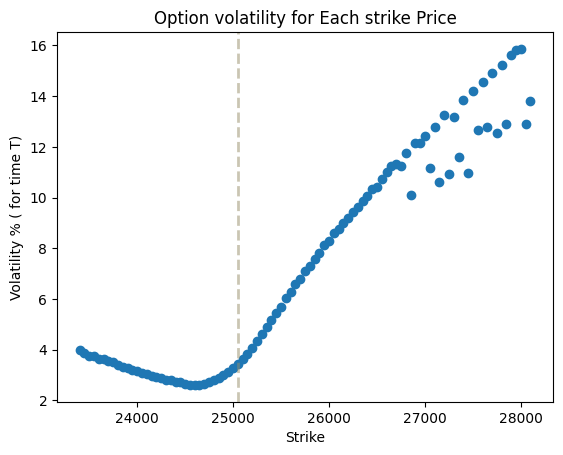

In [11]:
from matplotlib import pyplot as plt
plt.scatter(expiry_put["STRIKE \n"][:], expiry_put["IV"][:])
# plt.scatter(expiry_call["STRIKE \n"][:], expiry_call["IV"][:])
plt.title("Option volatility for Each strike Price")
plt.ylabel ("Volatility % ( for time T)") # look return in calculation of volatility function
plt.xlabel("Strike")
plt.axvline(x=25048, color="#968D68", linestyle='--', linewidth=2, alpha=0.5)

1. Looking at put curve we can say that  ( blue ) : Investors' willingness to pay more for downside protection
2. The market is in a downtrend or correction as prices are falling or there's heightened fear of a decline, investors are rushing to buy protective puts, driving up demand and implied volatility for puts relative to calls.
3. Minimal demand for upside speculation
4. looking at volatility comparision between put and call : Fear dominates greed in this market, investors are prioritize protection over speculation
5. Usually, deep ITM options have lower implied volatility because: They behave almost like the underlying (delta near 1.0) but here ITM puts doesn't show that case. ( perhaps due to low or no volume)

Visualizing Volume Traded for each option strike

In [12]:
volume_data= data[data["EXPIRY DATE \n"] == "2026-01-27"]
# print(volume_data)

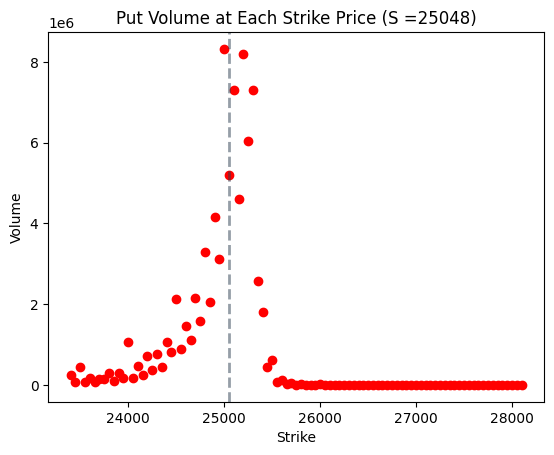

In [13]:
volume_data["K"]=pd.to_numeric(volume_data["STRIKE \n"].str.replace(",",""))
volume_data["V"] =pd.to_numeric(volume_data["VOLUME \n(Contracts)"].str.replace(",","").str.replace("-","0"))
volume_data_put= volume_data[volume_data["OPTION TYPE \n"]=="Put"].iloc[:,:]
volume_data_call =  volume_data[volume_data["OPTION TYPE \n"]=="Call"]

plt.scatter(volume_data_put["K"], volume_data_put["V"],color="red")
plt.title("Put Volume at Each Strike Price (S =25048)")
plt.ylabel ("Volume")
plt.xlabel("Strike")
# Add spot price line
plt.axvline(x=25048, color='#2C3E50', linestyle='--', linewidth=2, alpha=0.5)

1. The volume chart is nearly flat at the end, around 26k to 28K , as logically No one will buy from a seller who is selling security valued 25048 at 28000 ( why someone would ask for a loss) ( if you buy the optin, pay heavy premium , and if prices rise you will lose premium gradually) ( deep in the money )
2. and other way around, we are appraoching a low volume region with decrease in strike price, as it is far out of money, and its for the prices to reach, hard but not impoossible so no one purchase those option beside for purpose of hedging. ( person who sold  ( writer ) those option will gain if price remain above strike at expiry)

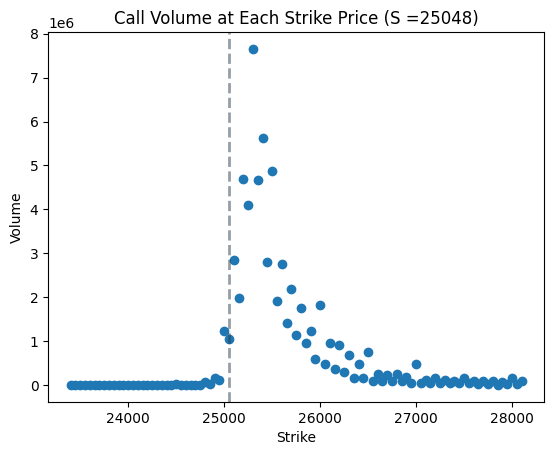

In [14]:
plt.scatter(volume_data_call["K"], volume_data_call["V"])
plt.title("Call Volume at Each Strike Price (S =25048)")
plt.ylabel ("Volume")
plt.xlabel("Strike") 
plt.axvline(x=25048, color='#2C3E50', linestyle='--', linewidth=2, alpha=0.5)

# Like t distrutbution


Text(0.5, 0, 'Strike')

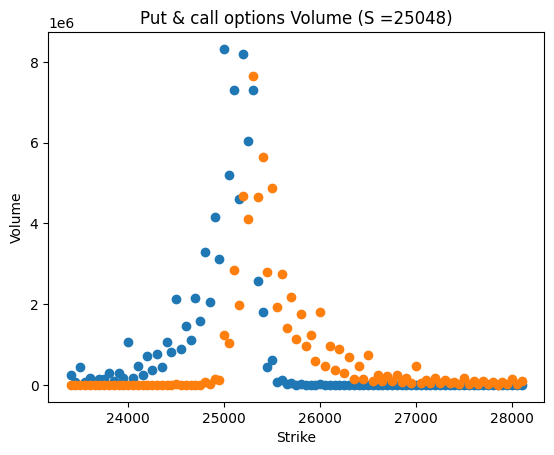

In [15]:
plt.scatter(volume_data_put["K"], volume_data_put["V"])
plt.scatter(volume_data_call["K"], volume_data_call["V"])
plt.title("Put & call options Volume (S =25048)")
plt.ylabel ("Volume")
plt.xlabel("Strike")